<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW4/Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 4

Title: Assignment Analysis

Name: Brennen Cramp

Date: 10/19/2026

---

# Analysis
---

1. Feature types in the UCI Heart Disease dataset introduce diversity among data especially due to the combination of continuous physiological telemetry. Combining continuous physiological telemetry which are mesaured on completely different scales and units (i.e. 'chol' in mg/dL and 'thalach' in bpm) compared to categorical indicators (i.e. 'cp' and 'thal') means that scaling across broad boundaries such as 'int64' is not effective due to the sensitivity and ranges of these different features. Each feature needs to be split into groups varying on their scaling sensitivity in relation to other features, unlike previous datasets. Thus, when Support Vector Machines are involved, feature scaling is fundamentally important due to the geometry-driven algorithms. They operate by computing the geometric Euclidean distance between patient data vectors in a multi-dimensional feature space to create an optimized hyperplane to seperate features. If unscaled data enters into an SVC, features with naturally larger numeric ranges will completely dominate the distance calculations. Without scaling, the SVC loses the ability to learn from tighter bounded features, leading to distorted decision boundaries and overall poor performance; thus proper scaling would ensure every clinical variable contributes equally to the distance metrics. In contrast, Decision Trees are completely invariant to feature scaling since it is a rule-based algorithm that partitions the feature space using axis-aligned splits, maximizing class purity. This means that Decision Trees evaluates one feature at a time, independently, so using a scaler on a column has no impact on where the boundaries will be set.

2. In raw medical environments, missing data would rarely present itself as clean, pre-coded blanks where it would take the form of hidden or implicit missing values, such as non-standard text placeholders (e.g., "?", "Unknown", NaN, or 999). These hidden artifacts present a challenge for machine learning workflows because strings like "?" are mixed into columns that should otherwise be entirely numeric and data loaders are forced to cast the entire column into a generic object/text datatype. If these values were left in the data, they will completely break numerical mathematical operations and even cause issues for downstream pipelines (I experienced this setback during the midterm assignment, at first) and if the rows were carelessly dropped, this skews the dataset completely by reducing the sample size. Luckily, this "?" value that was advised to handle for the assignment was not a factor for the dataset I imported (UCI Repository ID = 45) because each column was already set to be 'int64' or 'float64' and thus their values only contained 'NaN' if there was missing data. However, to factor for this safely without throwing away valuable samples, I applied tailored imputation strategies based strictly on the statistical and functional nature of each column type. For features such as 'chol', 'trestbps', and 'oldpeak' that typically have skewed numerical values, I chose the median strategy rather than the mean since this telemetry would often contain severely-skewed distributions due to outliers. Mean would be highly sensitive to these extremes and using it would artificially inflate the imputed values for typical patients. For categorical features such as 'ca', 'thal', and 'cp', I chose the most_frequent (mode) strategy. Features like these represent distinct, discrete categories or integer counts where fractional values are physically impossible. Imputing with the mode ensures that the missing field is filled with the most common value found in the training population, helping keep values discrete for the categorical vector.

3. A Support Vector Classifier (SVC) configured with a Radial Basis Function (RBF) kernel views classification through a geometric and high-dimensional lens. If the relationship between the clinical features and heart disease is non-linear, the data points cannot be separated by a straight line in the raw feature space. The RBF kernel would solve this by using a mathematical mapping function to project the data into an infinite-dimensional feature space. In that higher dimension, the algorithm finds the optimal hyperplane that maximizes the margin between healthy patients and patients with heart disease. Finally, when the hyperplane is projected into the original feature space, it forms smooth and continuous complex decision boundaries to allow the SVC to realize multi-variable interactions between the vitals of patients. In contrast, a Decision Tree operates through recursive axis-aligned partioning and instead of evaluating all features at once to draw a smooth curve, it processes features sequentially and individually. The algorithm looks at one feature at a time and makes a binary split where it then takes the resulting subsets of data and splits them again based on another feature via partitions. Due to each split evaluating one feature against a fixed threshold, the decision boundaries inside the feature space are orthogonal and visually, the boundary resembles a step-like staircase. Decision Trees cannot draw smooth curves and can only approximate them by making multiple jagged, rectangular boxes. With that in mind, these structural differences will create a major trade-off in medical applications. SVC has low interpretability but a high predictive adaptability where the inclusion of RBF in SVC creates a "black-box" model due to the which dimenion the decision hyperplane lies in being mathematically impossible to create a simple set of rules. This model cannot easily explain why a patient could be flagged as at-risk for heart disease and the trade-off is that the "hidden" boundary that is created via the hyperplane is often more accurate at predicting outcomes. In the case for Decision Trees, they have high interpretability but a lower predictive adaptability and can be seen as a "white-box" model where the steps are clear and easy to follow via its boolean logic path. However, its rigid, axis-aligned nature can easily overfit noise or fail to capture any subtle non-linear trends, not allowing it to adapt as easily as an SVC with RBF.

4. Tuning the hyperparameters of an SVC with an RBF kernel allows control of the balance between bias and variance and can ensure the model generalizes well to unseen patient test data, instead of memorizing noise in the training set. Using the StandardScaler framework, Task 7.1 found C=1 and gamma=0.01 were the best parameter settings for SVC. StandardScaler preserves the variance of the features, centering them around a mean of 0 and within this feature space, GridSearchCV converged on a balanced setup. A value of C=1 applies a moderate penalty for training misclassifications while gamma=0.01 establishes a wide radius of influence for each patient vector, creating smooth decision boundaries. Using the MinMaxScaler framework, Task 7.2 found C=0.1 and gamma='auto' were the best parameter settings for SVC. MinMaxScaler bounds all features strictly between 0 and 1, compressing the space and because the feature ranges are smaller, the algorithm requires a highly generalized approach to avoid overfitting. Task 7.2 selected a very low penalty of C=0.1, highly forgiving of training errors, and a low gamma='auto' value where these two settings force the model to favor a high-bias, low-variance strategy, making the decision boundary exceptionally smooth. The regularization parameter (C) dictates the penalty size assigned to training classification errors, serving as a strictness control. A high C value (low bias but high variance) makes the algorithm incredibly strict and forces the model to create a complex, small-margined decision boundary to classify every training point correctly. This minimizes the training error but risks capturing noise which leads to overfitting and a loss of generalization for new patients. A low C value (high bias but low vairance) allows for prioritizing finding of a smooth and wide decision boundary (very forgiving margin) over getting every training example perfect. For the kernel coefficient (gamma), it determines the radius of influence for individual training data points. A high gamma value (low bias but high variance) means a data point has a very localized and short-range influence where it forces the decision boundary to bend sharply around the points, often being the cause of extreme overfitting. A low gamma value (high bias but low variance) means each point has a broad and long-range influence where it makes the decision boundary consider points that are far away which results in a smoother curve. For unseen medical test data, when evaluating the StandardScaler and MinMaxScaler optimized configurations, a performance gap appears. During the cross-validation phase on the training set, MinMaxScaler achieved a slighlt higher score of 0.9236 to StandardScaler's 0.9215 but when deployed on the true test split, its performance dropped significantly to a test ROC-AUC score of 0.8766 to StandardScaler's 0.9058. This drop happened because the combination of C=0.1 and gamma='auto' over-regularized the model by making the boundary too smooth and forgiving, suffering from underfitting on the thresholds. This underfitting is also clearly visible in its postive-class (presence of heart disease) recall which fell to 68%. Conversely, the StandardScaler pipeline demonstrated excellent stability and generalization with its high ROC-AUC score of 0.9058 which was due to allowing a stricter error penality C=1 and an explicit kernel of gamma=0.01. This configuration also caught more true positive cases, raising the recall for the presence of heart disease to 75%.

5. When inspecting the Decision Tree feature importances, three primary clinical indicators ('ca_0.0', 'thal_7.0', and 'age'; also 'oldpeak' for the actual tree) drive the predicitive power for heart disease (for both scaling frameworks). 'ca_0.0' was evaluated to be the most critical feature in both models, holding a Gini importance of almost 0.3 and when checking the Decision Tree, the root split of the entire tree is based on ca_0.0 <= 0.5. 'ca_0.0' is the 'number of major vessels colored by Fluoroscopy' and tracks the blood flow through the major arteries and a value of 0 for 'ca' indicates that zero major vessels are blocked and accurately represents the model's primary filter for diagnosing heart disease. The next major indicator is 'thal_7.0' as the second most important metric which an importance of around 0.115. 'thal_7.0' represents a "temporary lack of blood flow to the heart muscle during stress" and in the Decision Tree's right of the root branch (i.e. when patients have zero blocked major vessels), if a patient does have this defect, they are routed to a branch where the majority of patients have the disease present. For the next major indicator(s), 'age' for the "Decision Tree Feature Importances" graphs and 'oldpeak' (ST depression) for the "Decision Tree CLassification Path" graphs were viewed with importances of roughly 0.11 for 'age' and 0.08 for 'oldpeak'. 'age' of the patient has the third highest importance calculated while 'oldpeak' has the sixth highest underneath 'chol' and 'cp_4.0' but is an important factor in the third level (level=2) of the Decision Tree. 'oldpeak' meausres the "ST depression induced by exercise relative to rest" which helps quantify the stress on a patient and at this level, isolates hgiher-risk patients by showing the severity of the disease classification. In the case of preventative screening insights for cardiologists, these findings suggest a clear workflow for them. Cardiologists should prioritize imaging for 'ca' and 'thal' vitals because they dominate the top splits and are known to be the biggeset signs of heart disease in patients. Thus, if a patient comes to their office with any blood flow issues or previous signs of heart issues, these 2 values are what they need to screen for. A step down from there, they should run screenings for chest pain 'cp_4.0' which appears prominently on the left side of the Decision Tree and indicates that many patients with heart disease do not show the typical warning signs so the caridologists should not rule out a disease if the patients does not have chest pain whereas underlying metrics like 'ca' and 'oldpeak' are abnormal and means the cardiologist should seek additonal screenings. Finally, vitals like 'trestbps' and 'chol' have lower relative importance scores for this tree and suggests that while baseline vitals are useful long-term risk indicators, active telemetry metrics (like 'oldpeak' and 'thalach') are far more reliable for making an accurate diagnostic classification.


# **Decision Tree Interpretation & Feature Importances (StandardScaler) (Task 8.1):**

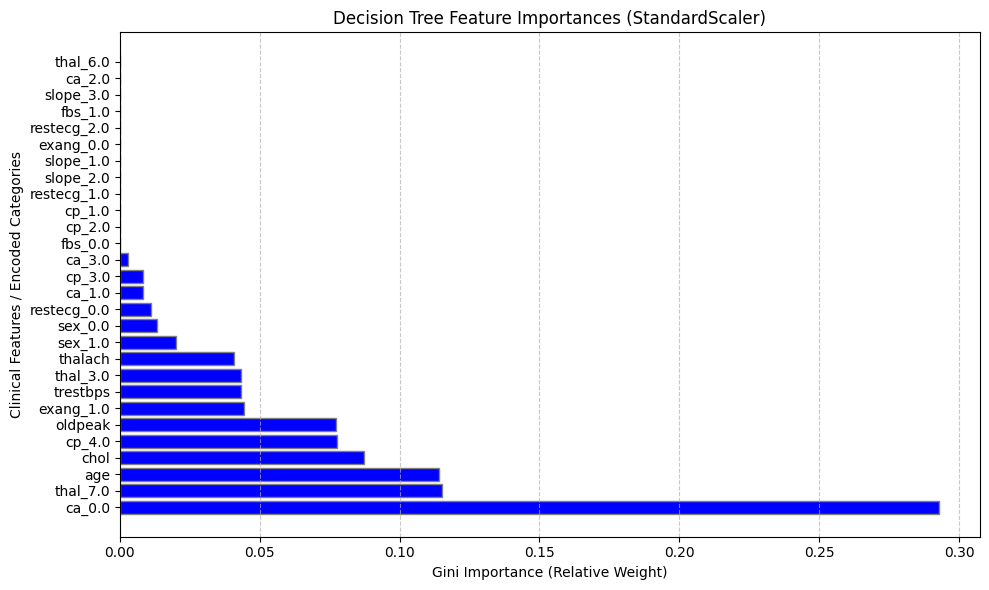

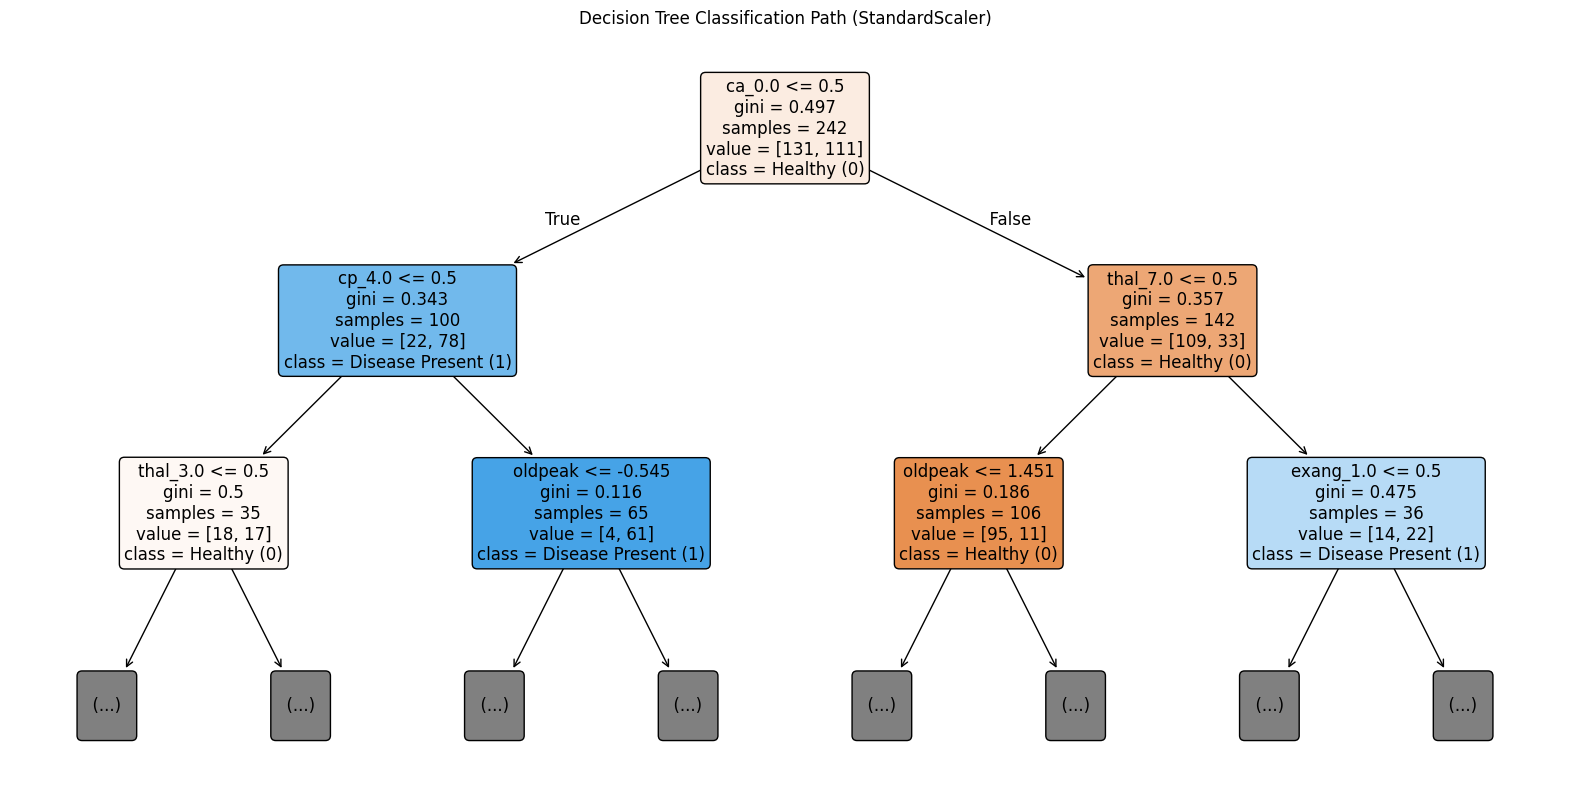

# **Decision Tree Interpretation & Feature Importances (MinMaxScaler) (Task 8.2):**

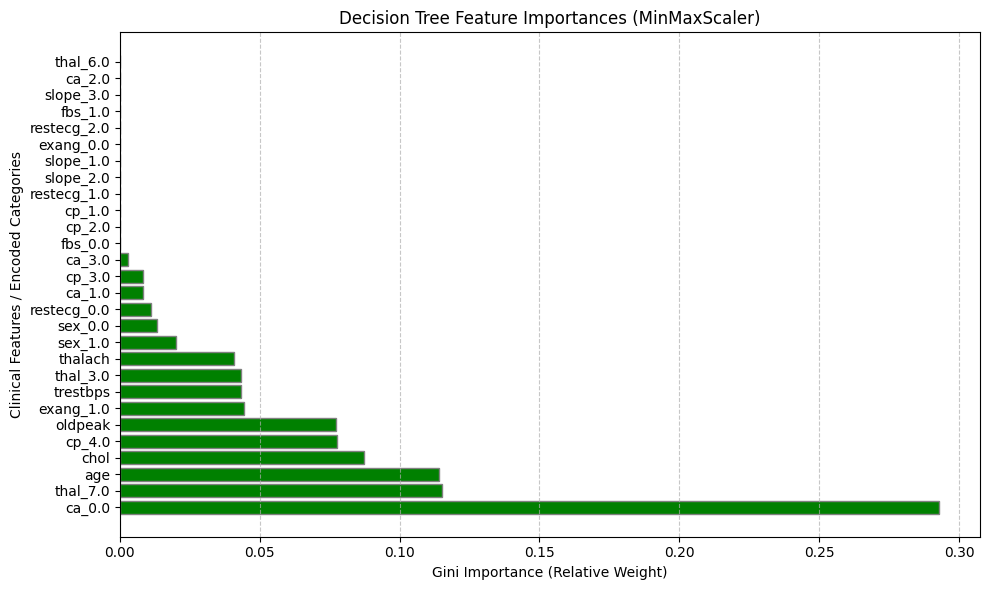

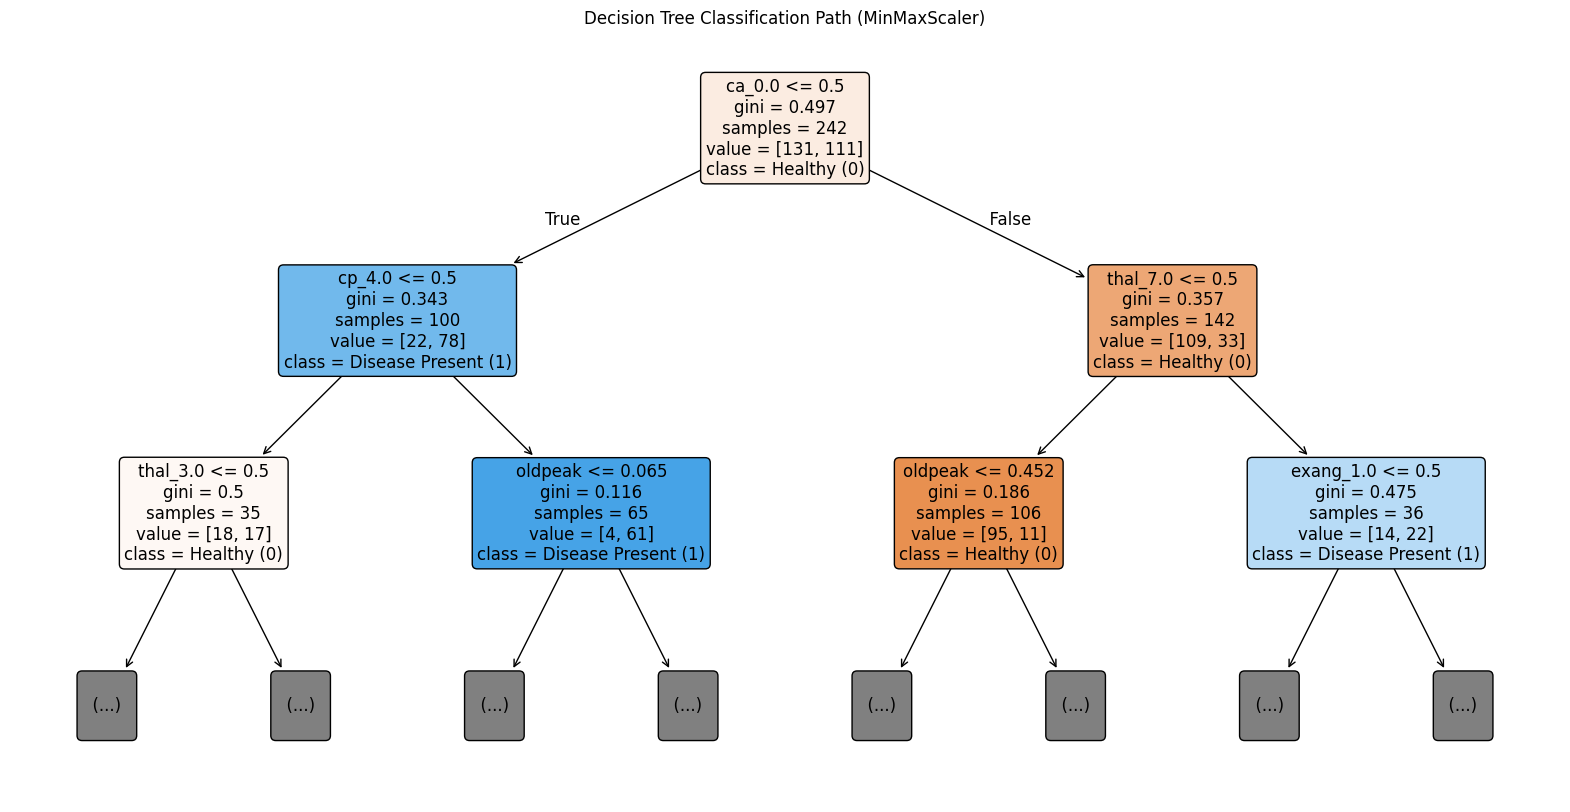